We generate probabilities with the sigmoid function h(x)
we use cross entropy instead of mean squared error

# Logistic Regression

In [8]:
import numpy as np

def sigmoid(x):
    return 1/(1+np.exp(-x))

class LogisticRegression():

    def __init__(self, lr=0.001, n_iters=1000):
        self.lr = lr
        self.n_iters = n_iters
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features) #initialize w as 0s
        self.bias = 0

        for _ in range(self.n_iters):
          linear_pred = np.dot(X, self.weights) + self.bias
          predictions = sigmoid(linear_pred)

          dw = (1/n_samples) * np.dot(X.T, (predictions - y))
          db = (1/n_samples) * np.sum(predictions-y)

          #UPDATE VALUES
          self.weights -= self.lr * dw
          self.bias -= self.lr * db #(self.bias-self.lr*db)

    def predict(self, X):
        linear_pred = np.dot(X, self.weights) + self.bias
        y_pred = sigmoid(linear_pred) #here are the probabilities 0-1
        class_pred = [0 if y<=0.5 else 1 for y in y_pred]
        return class_pred


# Testing/Train

In [28]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import datasets
import matplotlib.pyplot as plt
#from LogisticRegression import LogisticRegression #if algorithm is in another file

bc = datasets.load_breast_cancer() #dataset imported from sklearn
X,y = bc.data, bc.target #X and y respectively
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 1234) #train_test_split takes samples from the same dataset. It doesn't create new data points. Instead, it randomly shuffles the dataset and then divides it into two subsets: a training set and a testing set.


#classifier
clf = LogisticRegression(lr=0.01) #you can change learning rate
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

def accuracy(y_pred, y_test):
    return np.sum(y_pred==y_test)/len(y_test)

acc = accuracy(y_pred, y_test)
print(acc)



<ipython-input-8-26677c387c52>:4: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-x))


0.9210526315789473


# Plotting

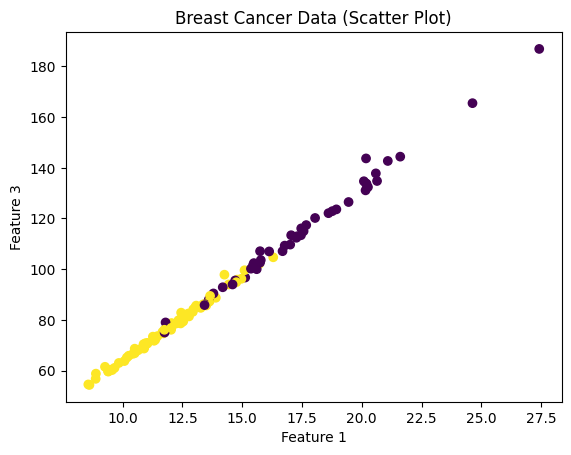

In [31]:
# Select features for plotting (assuming features 0 and 2 are meaningful)
features = [0, 2]  # Feature indices

# Create scatter plot
plt.scatter(X_test[:, features[0]], X_test[:, features[1]], c=y_test)
plt.xlabel("Feature {}".format(features[0] + 1))  # Add 1 for feature number clarity
plt.ylabel("Feature {}".format(features[1] + 1))
plt.title("Breast Cancer Data (Scatter Plot)")
plt.show()

Thiis exactly what you get from creating and training the model in terms of visualizing the data itself.

Here's a breakdown of what you achieve with this code:

Feature Selection: You choose specific features (columns) from the test data (X_test) to plot. In this case, features = [0, 2] selects the first and third features for visualization.

1. Scatter Plot Creation: The code creates a scatter plot using plt.scatter. Each data point in the plot represents a sample from the test set. The x-axis corresponds to the value of the first chosen feature, and the y-axis corresponds to the value of the second chosen feature.

2. Color Coding by Target Variable: The c=y_test argument specifies that the color of each point should be based on the corresponding target variable (y_test). This allows you to visually distinguish between samples belonging to different classes (malignant and benign in this case).

3. Labeling and Title: The code adds labels to the x and y axes indicating which features they represent (shifted by 1 for clarity) and a title for the plot ("Breast Cancer Data (Scatter Plot)").

By visualizing the data, you can explore the distribution of the features and potentially observe patterns or differences between the classes.

However, this visualization doesn't directly show the model's predictions.

##Confusion matrix
A confusion matrix is a table that summarizes the performance of a classification model. It shows the number of true positives, true negatives, false positives, and false negatives.

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
plt.matshow(cm)
plt.title("Confusion Matrix")

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()

##scatter plot with predicted labels

This code will plot the data points with the same x and y coordinates as before, but the color of each point will now be determined by the predicted class label (from y_pred) instead of the actual target label (from y_test). This allows you to visualize how well the model is separating the classes based on its predictions.

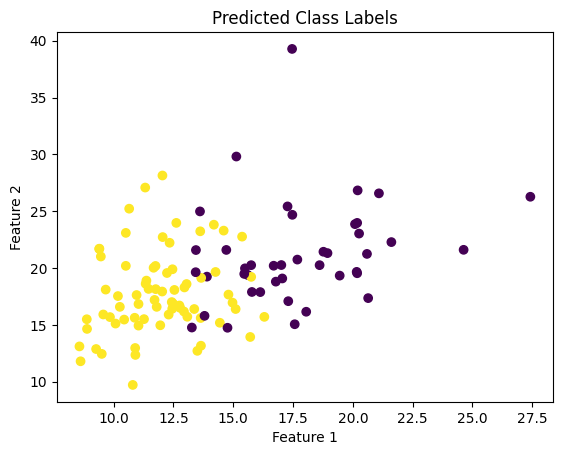

In [33]:

# Assuming you have X_test, y_test, and y_pred

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred, cmap='viridis')
plt.title("Predicted Class Labels")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Theory

###Steps
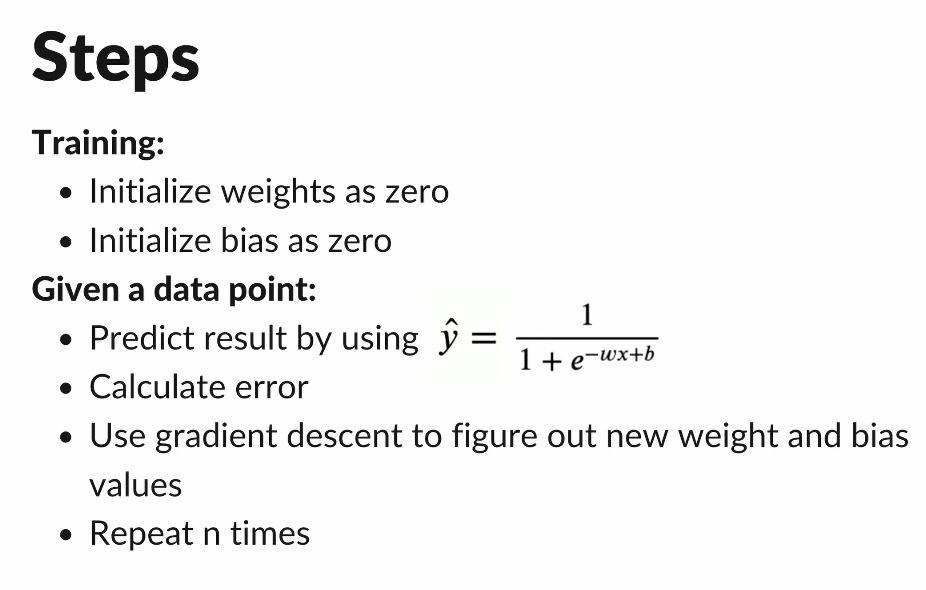
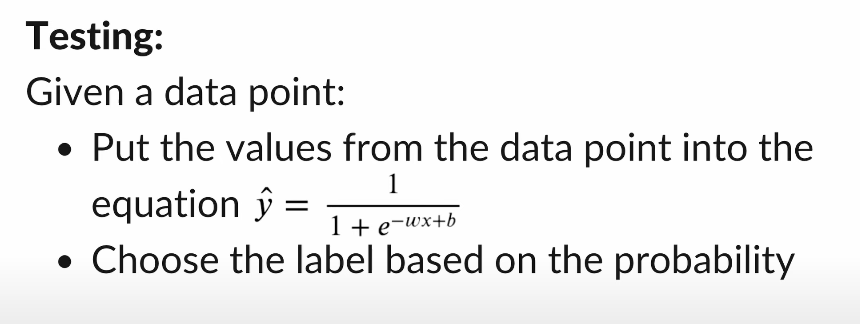

The learning rate tells you how fast to move in one direction to reach the minimum error, that is minimum J(w) 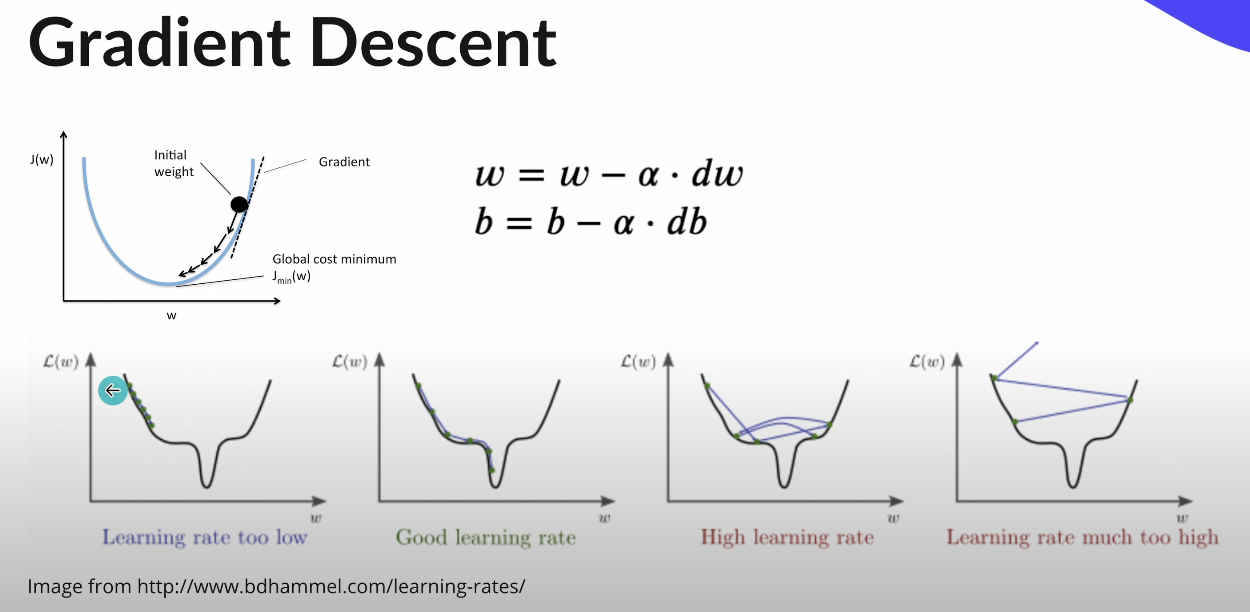



Gradient Descent minimizes the error J(w) given a vaue w

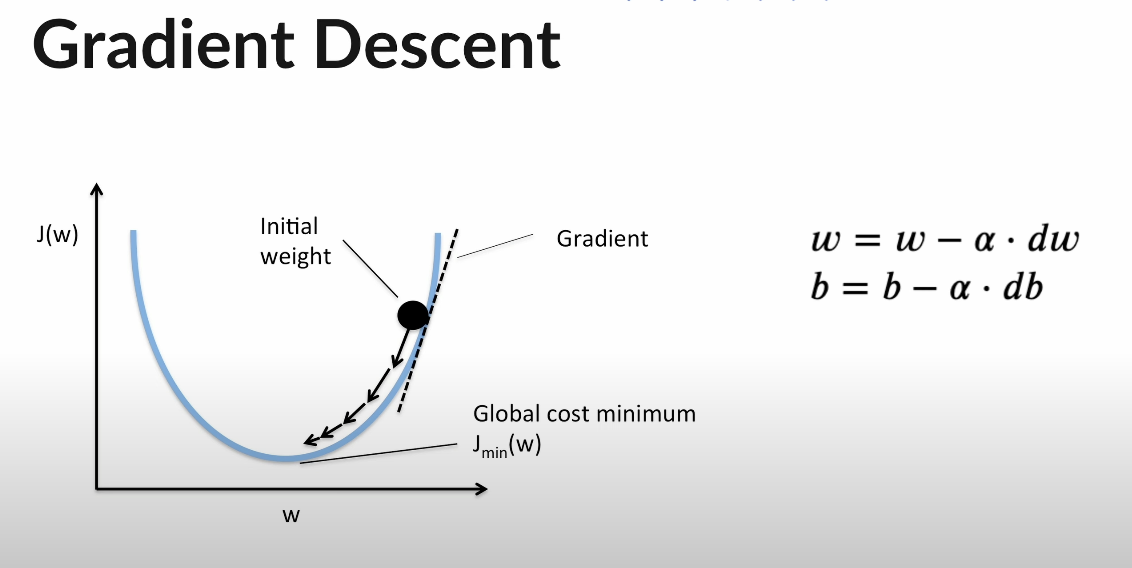

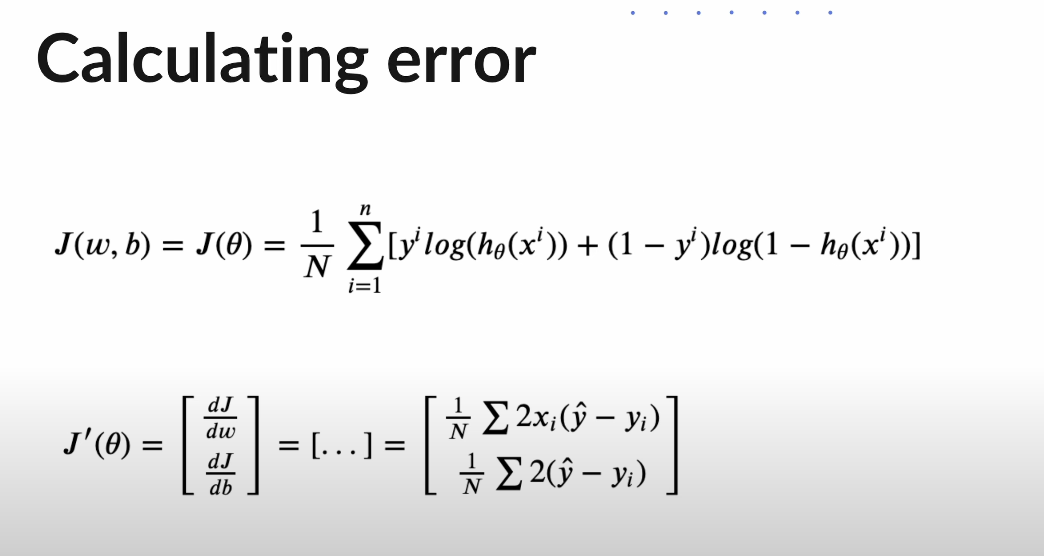